# Deep Learning Week 1

## Neural Network Foundations & PyTorch

### Assignment 1 + Mini Project 1

**Mini Project:** Numerical Pattern Predictor

**Framework:** PyTorch

**Environment:** Google Colab

In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
print("PyTorch version:", torch.__version__)

PyTorch version: 2.11.0+cpu


## 2. PyTorch Tensor Operations

A tensor is the basic data structure used by PyTorch to store numerical data.

We will perform:
- Tensor creation
- Reshaping
- Matrix multiplication
- Indexing

In [4]:
#Tensor creation
x=torch.tensor([
    [1,2,3],
    [4,5,6]
])
print("Tensor:")
print(x)
print("\nShape of tensor:")
print(x.shape)

Tensor:
tensor([[1, 2, 3],
        [4, 5, 6]])

Shape of tensor:
torch.Size([2, 3])


In [5]:
# Tensor reshaping

reshaped_x = x.reshape(3, 2)

print("Original tensor:")
print(x)

print("\nReshaped tensor:")
print(reshaped_x)

print("\nOriginal shape:", x.shape)
print("New shape:", reshaped_x.shape)

Original tensor:
tensor([[1, 2, 3],
        [4, 5, 6]])

Reshaped tensor:
tensor([[1, 2],
        [3, 4],
        [5, 6]])

Original shape: torch.Size([2, 3])
New shape: torch.Size([3, 2])


In [6]:
#Tensor Multiplication
a=torch.tensor([
    [1,2],
    [3,4]
])
b=torch.tensor([
    [5,6],
    [7,8]
])
result=torch.matmul(a,b)
print("Tensor A:")
print(a)
print("\nTensor B:")
print(b)
print("\nMatrix multiplication result:")
print(result)

Tensor A:
tensor([[1, 2],
        [3, 4]])

Tensor B:
tensor([[5, 6],
        [7, 8]])

Matrix multiplication result:
tensor([[19, 22],
        [43, 50]])


In [7]:
# Tensor indexing

print("First row:", x[0])
print("Second row:", x[1])

print("Element at row 1, column 1:", x[0, 0])
print("Element at row 2, column 1:", x[1, 0])
print("Element at row 2, column 3:", x[1, 2])

First row: tensor([1, 2, 3])
Second row: tensor([4, 5, 6])
Element at row 1, column 1: tensor(1)
Element at row 2, column 1: tensor(4)
Element at row 2, column 3: tensor(6)


## 3. Generate Synthetic Regression Data

For this project, we will generate our own numerical dataset.

The data follows the relationship:

y = 2x + 1

Random noise is added to make the data more realistic.

The neural network will learn this relationship from the training data and predict outputs for unseen inputs.

In [10]:
  #Generate Synthetic Regression Data
torch.manual_seed(42)

x=torch.linspace(0,10,100).reshape(-1,1)

noise=torch.randn_like(x)*0.5

y=2*x+1+noise

print("First 10 input values:")
print(x[:10])
print("\nFirst 10 output values:")
print(y[:10])

print("\nInput shape:", x.shape)
print("Output shape:", y.shape)


First 10 input values:
tensor([[0.0000],
        [0.1010],
        [0.2020],
        [0.3030],
        [0.4040],
        [0.5051],
        [0.6061],
        [0.7071],
        [0.8081],
        [0.9091]])

First 10 output values:
tensor([[1.9635],
        [1.9457],
        [1.8544],
        [0.5533],
        [2.1473],
        [1.3928],
        [2.1906],
        [1.6118],
        [2.2401],
        [3.6425]])

Input shape: torch.Size([100, 1])
Output shape: torch.Size([100, 1])


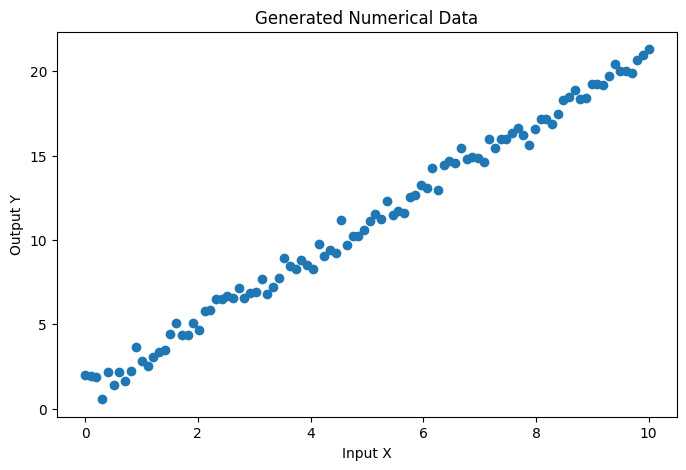

In [14]:
# Visualize the generated data

plt.figure(figsize=(8, 5))

plt.scatter(x.numpy(), y.numpy())

plt.xlabel("Input X")
plt.ylabel("Output Y")
plt.title("Generated Numerical Data")

plt.show()

## 4. Split Data into Training, Validation, and Testing Sets
The dataset is divided into three parts:
- Training set: 70%
- Validation set: 15%
- Testing set: 15%

In [15]:
# Split the dataset

n = len(x)

train_end = int(0.70 * n)
val_end = int(0.85 * n)

X_train = x[:train_end]
y_train = y[:train_end]

X_val = x[train_end:val_end]
y_val = y[train_end:val_end]

X_test = x[val_end:]
y_test = y[val_end:]

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

Training samples: 70
Validation samples: 15
Testing samples: 15


## 5. Build the Neural Network

We will build a simple feedforward neural network using PyTorch.

Architecture:

Input Layer → Hidden Layer → Output Layer

The hidden layer contains 16 neurons and uses the ReLU activation function.

In [17]:
class NumericalPredictor(nn.Module):
  def __init__(self):
    super().__init__()

    self.network=nn.Sequential(
        nn.Linear(1,16),
        nn.ReLU(),
        nn.Linear(16,1)
    )
  def forward(self,x):
    return self.network(x)
model=NumericalPredictor()
print(model)

NumericalPredictor(
  (network): Sequential(
    (0): Linear(in_features=1, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=1, bias=True)
  )
)


## 6. Loss Function

We use Mean Squared Error (MSE) to measure the difference between the actual and predicted values.

A lower loss means the predictions are closer to the actual values.

In [18]:
#Define the loss function
loss_function=nn.MSELoss()
print("Loss function:",loss_function)

Loss function: MSELoss()


## 7. Optimizer

The Adam optimizer is used to update the model's weights during training.

The first experiment uses a learning rate of 0.01.

In [19]:
# Define optimizer

optimizer = optim.Adam(
    model.parameters(),
    lr=0.01
)

print("Learning rate:", 0.01)

Learning rate: 0.01


## 8. Train the Neural Network

The model is trained for 100 epochs.

During each epoch:
1. The model makes predictions.
2. Training loss is calculated.
3. Gradients are calculated using backpropagation.
4. The optimizer updates the model parameters.
5. Validation loss is calculated.

In [20]:
# Training the model

epochs = 100

train_losses = []
val_losses = []

for epoch in range(epochs):

    # Training mode
    model.train()

    # Forward propagation
    predictions = model(X_train)

    # Calculate training loss
    train_loss = loss_function(predictions, y_train)

    # Clear previous gradients
    optimizer.zero_grad()

    # Backpropagation
    train_loss.backward()

    # Update weights
    optimizer.step()

    # Validation
    model.eval()

    with torch.no_grad():
        val_predictions = model(X_val)
        val_loss = loss_function(val_predictions, y_val)

    # Store losses
    train_losses.append(train_loss.item())
    val_losses.append(val_loss.item())

    # Display progress
    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Training Loss: {train_loss.item():.4f} | "
            f"Validation Loss: {val_loss.item():.4f}"
        )

Epoch 10/100 | Training Loss: 50.4002 | Validation Loss: 156.1753
Epoch 20/100 | Training Loss: 26.2885 | Validation Loss: 80.7794
Epoch 30/100 | Training Loss: 6.6273 | Validation Loss: 18.9643
Epoch 40/100 | Training Loss: 0.6140 | Validation Loss: 0.1821
Epoch 50/100 | Training Loss: 1.5188 | Validation Loss: 1.8582
Epoch 60/100 | Training Loss: 0.5404 | Validation Loss: 0.1818
Epoch 70/100 | Training Loss: 0.4727 | Validation Loss: 0.7405
Epoch 80/100 | Training Loss: 0.4325 | Validation Loss: 0.4947
Epoch 90/100 | Training Loss: 0.3723 | Validation Loss: 0.1988
Epoch 100/100 | Training Loss: 0.3594 | Validation Loss: 0.1816


## 9. Training and Validation Loss Curve

The loss curve shows how the training and validation losses change as the number of epochs increases.

A decreasing loss generally indicates that the model is learning the relationship in the data.

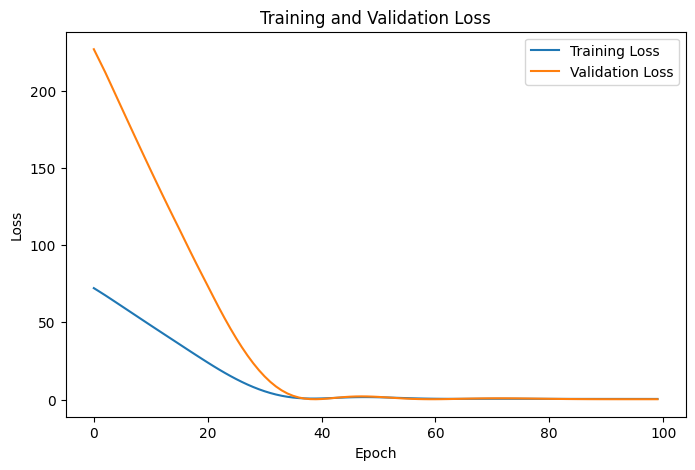

In [21]:
# Plot training and validation loss

plt.figure(figsize=(8, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")

plt.legend()
plt.show()

## 10. Prediction on Unseen Test Data

The test dataset was not used during training. We use it to evaluate how well the trained model can predict outputs for unseen inputs.

In [22]:
# Make predictions on unseen test data

model.eval()

with torch.no_grad():
    test_predictions = model(X_test)

test_loss = loss_function(test_predictions, y_test)

print("Test Loss:", test_loss.item())

Test Loss: 0.22341910004615784


In [23]:
model(X_test)

tensor([[17.9464],
        [18.1396],
        [18.3328],
        [18.5260],
        [18.7192],
        [18.9124],
        [19.1056],
        [19.2988],
        [19.4920],
        [19.6852],
        [19.8784],
        [20.0716],
        [20.2648],
        [20.4580],
        [20.6512]], grad_fn=<AddmmBackward0>)

In [24]:
test_loss

tensor(0.2234)

In [25]:
# Display actual and predicted values

print("Actual vs Predicted")

for i in range(len(X_test)):
    print(
        f"Input: {X_test[i].item():.2f} | "
        f"Actual: {y_test[i].item():.2f} | "
        f"Predicted: {test_predictions[i].item():.2f}"
    )

Actual vs Predicted
Input: 8.59 | Actual: 18.46 | Predicted: 17.95
Input: 8.69 | Actual: 18.91 | Predicted: 18.14
Input: 8.79 | Actual: 18.35 | Predicted: 18.33
Input: 8.89 | Actual: 18.44 | Predicted: 18.53
Input: 8.99 | Actual: 19.27 | Predicted: 18.72
Input: 9.09 | Actual: 19.28 | Predicted: 18.91
Input: 9.19 | Actual: 19.21 | Predicted: 19.11
Input: 9.29 | Actual: 19.72 | Predicted: 19.30
Input: 9.39 | Actual: 20.42 | Predicted: 19.49
Input: 9.49 | Actual: 19.99 | Predicted: 19.69
Input: 9.60 | Actual: 20.04 | Predicted: 19.88
Input: 9.70 | Actual: 19.90 | Predicted: 20.07
Input: 9.80 | Actual: 20.66 | Predicted: 20.26
Input: 9.90 | Actual: 20.97 | Predicted: 20.46
Input: 10.00 | Actual: 21.31 | Predicted: 20.65


## 11. Actual vs Predicted Graph

The following graph compares the actual outputs from the test dataset with the outputs predicted by the trained neural network.

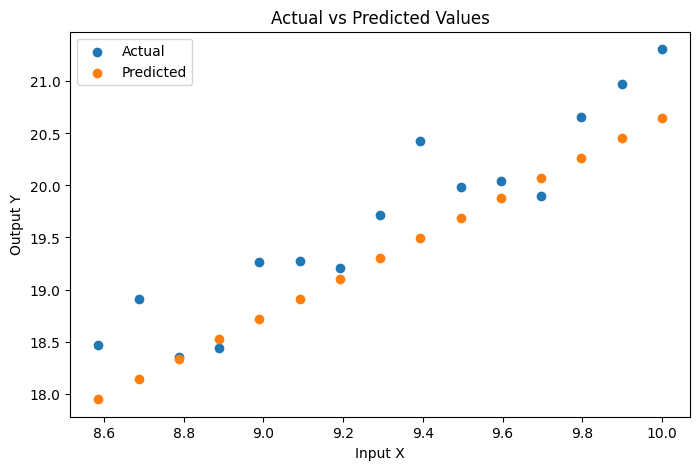

In [26]:
# Actual vs Predicted graph

plt.figure(figsize=(8, 5))

plt.scatter(
    X_test.numpy(),
    y_test.numpy(),
    label="Actual"
)

plt.scatter(
    X_test.numpy(),
    test_predictions.numpy(),
    label="Predicted"
)

plt.xlabel("Input X")
plt.ylabel("Output Y")
plt.title("Actual vs Predicted Values")

plt.legend()
plt.show()

## 12. Learning Rate Comparison

Two learning rates are tested to understand their effect on neural network training.

- Experiment 1: Learning rate = 0.01
- Experiment 2: Learning rate = 0.001

Both models use the same dataset, architecture, loss function, and number of epochs.

In [28]:
# Create a new model for the second experiment

model_lr001 = NumericalPredictor()

# Use a smaller learning rate
optimizer_lr001 = optim.Adam(
    model_lr001.parameters(),
    lr=0.001
)

epochs = 100

train_losses_lr001 = []
val_losses_lr001 = []

for epoch in range(epochs):

    # Training mode
    model_lr001.train()

    # Forward propagation
    predictions = model_lr001(X_train)

    # Calculate training loss
    train_loss = loss_function(predictions, y_train)

    # Clear previous gradients
    optimizer_lr001.zero_grad()

    # Backpropagation
    train_loss.backward()

    # Update weights
    optimizer_lr001.step()

    # Validation
    model_lr001.eval()

    with torch.no_grad():
        val_predictions = model_lr001(X_val)
        val_loss = loss_function(val_predictions, y_val)

    # Store losses
    train_losses_lr001.append(train_loss.item())
    val_losses_lr001.append(val_loss.item())

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Training Loss: {train_loss.item():.4f} | "
            f"Validation Loss: {val_loss.item():.4f}"
        )

Epoch 10/100 | Training Loss: 75.0367 | Validation Loss: 242.1659
Epoch 20/100 | Training Loss: 72.0468 | Validation Loss: 232.3692
Epoch 30/100 | Training Loss: 69.1074 | Validation Loss: 222.7326
Epoch 40/100 | Training Loss: 66.1995 | Validation Loss: 213.2065
Epoch 50/100 | Training Loss: 63.3161 | Validation Loss: 203.7791
Epoch 60/100 | Training Loss: 60.4521 | Validation Loss: 194.4483
Epoch 70/100 | Training Loss: 57.5993 | Validation Loss: 185.2170
Epoch 80/100 | Training Loss: 54.7378 | Validation Loss: 176.0916
Epoch 90/100 | Training Loss: 51.8307 | Validation Loss: 166.9089
Epoch 100/100 | Training Loss: 48.9097 | Validation Loss: 157.5130


In [29]:
# Evaluate the second model on unseen test data

model_lr001.eval()

with torch.no_grad():
    test_predictions_lr001 = model_lr001(X_test)

test_loss_lr001 = loss_function(
    test_predictions_lr001,
    y_test
)

print("Test Loss with learning rate 0.001:",
      test_loss_lr001.item())

Test Loss with learning rate 0.001: 225.8647918701172


## 13. Comparison of Learning Rates

The training loss curves for the two learning rates are compared below.

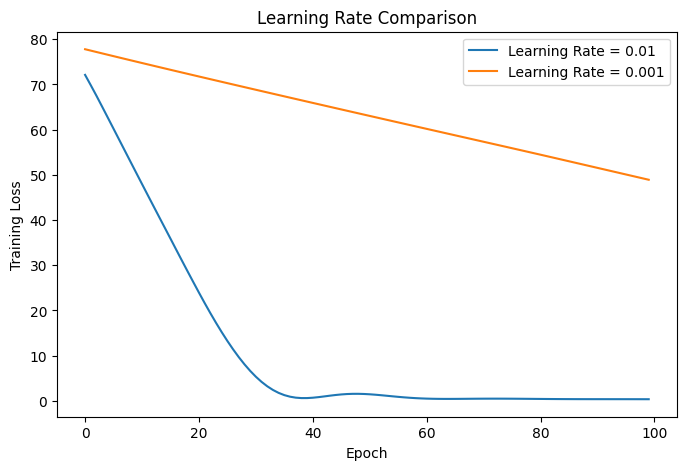

In [30]:
# Compare training loss for both learning rates

plt.figure(figsize=(8, 5))

plt.plot(
    train_losses,
    label="Learning Rate = 0.01"
)

plt.plot(
    train_losses_lr001,
    label="Learning Rate = 0.001"
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Learning Rate Comparison")

plt.legend()
plt.show()

In [31]:
# Compare final results

print("Learning Rate Comparison")
print("-" * 45)

print(f"Learning Rate 0.01  | Test Loss: {test_loss.item():.4f}")
print(f"Learning Rate 0.001 | Test Loss: {test_loss_lr001.item():.4f}")

Learning Rate Comparison
---------------------------------------------
Learning Rate 0.01  | Test Loss: 0.2234
Learning Rate 0.001 | Test Loss: 225.8648


## 14. Extended Training for Learning Rate = 0.001

The learning rate of 0.001 showed slower convergence within 100 epochs.
Therefore, the model is trained for more epochs to observe whether it
can eventually learn the numerical relationship.

In [32]:
# Train a new model with learning rate = 0.001 for 1000 epochs

model_lr001_long = NumericalPredictor()

optimizer_lr001_long = optim.Adam(
    model_lr001_long.parameters(),
    lr=0.001
)

epochs_long = 1000

train_losses_lr001_long = []
val_losses_lr001_long = []

for epoch in range(epochs_long):

    model_lr001_long.train()

    predictions = model_lr001_long(X_train)

    train_loss = loss_function(predictions, y_train)

    optimizer_lr001_long.zero_grad()

    train_loss.backward()

    optimizer_lr001_long.step()

    model_lr001_long.eval()

    with torch.no_grad():
        val_predictions = model_lr001_long(X_val)
        val_loss = loss_function(val_predictions, y_val)

    train_losses_lr001_long.append(train_loss.item())
    val_losses_lr001_long.append(val_loss.item())

    if (epoch + 1) % 100 == 0:
        print(
            f"Epoch {epoch + 1}/{epochs_long} | "
            f"Training Loss: {train_loss.item():.4f} | "
            f"Validation Loss: {val_loss.item():.4f}"
        )

Epoch 100/1000 | Training Loss: 47.3643 | Validation Loss: 161.8917
Epoch 200/1000 | Training Loss: 20.2471 | Validation Loss: 70.3801
Epoch 300/1000 | Training Loss: 4.7567 | Validation Loss: 16.9778
Epoch 400/1000 | Training Loss: 0.8284 | Validation Loss: 2.2900
Epoch 500/1000 | Training Loss: 0.4667 | Validation Loss: 0.4977
Epoch 600/1000 | Training Loss: 0.3554 | Validation Loss: 0.2725
Epoch 700/1000 | Training Loss: 0.2956 | Validation Loss: 0.1935
Epoch 800/1000 | Training Loss: 0.2737 | Validation Loss: 0.1790
Epoch 900/1000 | Training Loss: 0.2678 | Validation Loss: 0.1874
Epoch 1000/1000 | Training Loss: 0.2662 | Validation Loss: 0.1954


In [33]:
# Evaluate the extended 0.001 model

model_lr001_long.eval()

with torch.no_grad():
    test_predictions_lr001_long = model_lr001_long(X_test)

test_loss_lr001_long = loss_function(
    test_predictions_lr001_long,
    y_test
)

print("Test Loss with learning rate 0.001 after 1000 epochs:",
      test_loss_lr001_long.item())

Test Loss with learning rate 0.001 after 1000 epochs: 0.13885703682899475


## 15. Learning Rate Comparison

The two learning rates produced different training behaviors.

The learning rate of 0.01 reduced the loss quickly and achieved a test loss of approximately 0.2234 after 100 epochs.

The learning rate of 0.001 converged more slowly. After extending the training to 1000 epochs, it achieved a lower test loss of approximately 0.1389.

This shows that the learning rate affects both the speed of convergence and the final performance of the model.

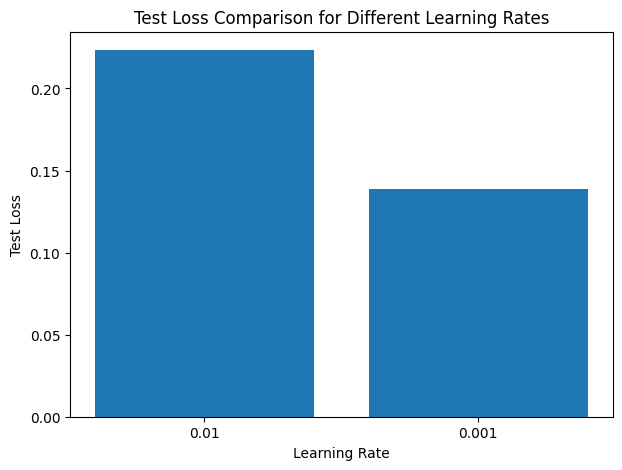

In [34]:
# Final learning rate comparison

learning_rates = ["0.01", "0.001"]
test_losses = [
    test_loss.item(),
    test_loss_lr001_long.item()
]

plt.figure(figsize=(7, 5))

plt.bar(learning_rates, test_losses)

plt.xlabel("Learning Rate")
plt.ylabel("Test Loss")
plt.title("Test Loss Comparison for Different Learning Rates")

plt.show()

## 16. Final Actual vs Predicted Results

The trained model is evaluated on the unseen test dataset. The graph compares the actual outputs with the predictions generated by the neural network.

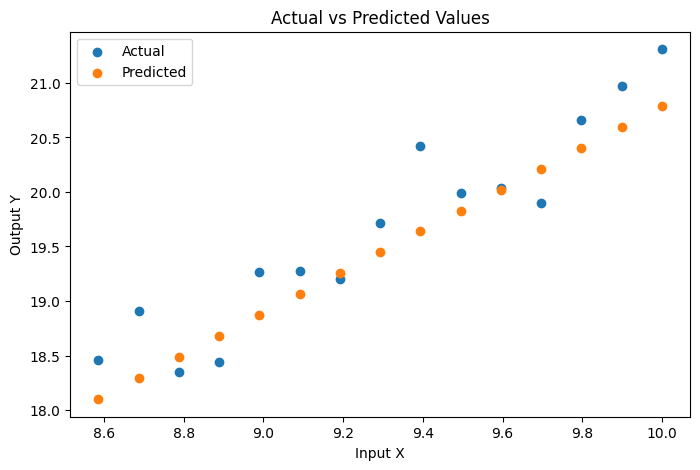

In [35]:
# Final actual vs predicted graph

plt.figure(figsize=(8, 5))

plt.scatter(
    X_test.numpy(),
    y_test.numpy(),
    label="Actual"
)

plt.scatter(
    X_test.numpy(),
    test_predictions_lr001_long.numpy(),
    label="Predicted"
)

plt.xlabel("Input X")
plt.ylabel("Output Y")
plt.title("Actual vs Predicted Values")

plt.legend()

plt.show()

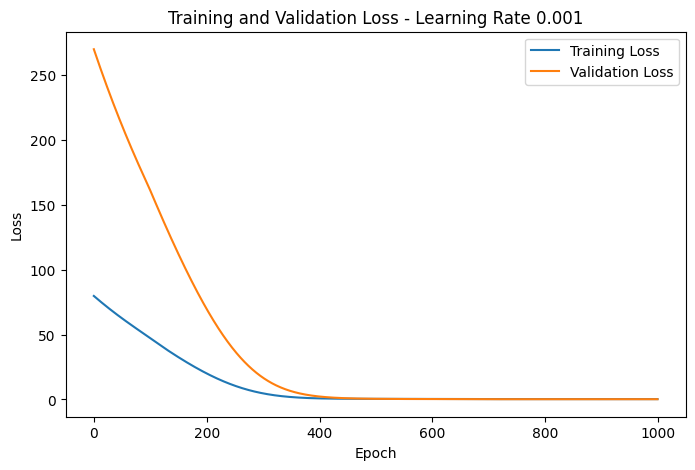

In [36]:
# Final loss curve for learning rate = 0.001

plt.figure(figsize=(8, 5))

plt.plot(
    train_losses_lr001_long,
    label="Training Loss"
)

plt.plot(
    val_losses_lr001_long,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss - Learning Rate 0.001")

plt.legend()

plt.show()

## 17. Results and Discussion

The Numerical Pattern Predictor successfully learned the relationship
between the input and output values from the generated numerical dataset.

The first experiment used a learning rate of 0.01 for 100 epochs and
achieved a test loss of approximately 0.2234. The model learned the
pattern relatively quickly.

The second experiment used a smaller learning rate of 0.001. After
100 epochs, the model was still learning slowly, so the training was
extended to 1000 epochs. The final test loss was approximately 0.1389.

The lower learning rate required more training epochs but eventually
achieved a lower test loss. This demonstrates that the learning rate
has an important effect on the speed of convergence and model
performance.

The actual-versus-predicted graph shows that the model's predictions
are close to the actual test values, indicating that the neural network
successfully learned the underlying numerical relationship.

## 18. Conclusion

A simple feedforward neural network was successfully implemented using
PyTorch to predict outputs from generated numerical data.

The project covered tensor operations, dataset splitting, neural network
construction, forward propagation, loss calculation, backpropagation,
optimization, validation, and prediction on unseen data.

The experiments demonstrated how different learning rates affect the
training process. The model with a learning rate of 0.001 achieved the
lowest test loss after extended training.

Overall, the project demonstrates the basic workflow of training a
neural network for a regression problem using PyTorch.